# Final Project — Predicting the Severity of Road Accidents (UK, 2018)

**Problem:** given the conditions of a road accident (road, weather, light, speed limit, time, vehicles and drivers involved), predict whether the accident will be **Serious / Fatal** or **Slight**.

**Why it matters:** the police and road authorities can use the model to find which conditions make an accident dangerous and where to focus safety measures.

**Type:** binary classification with imbalanced classes (about 20% Serious/Fatal vs 80% Slight).

**Data:** UK Department for Transport *Road Safety Data 2018* — 3 linked tables (joined with `Accident_Index`):
| Table | Rows | One row is... |
|---|---|---|
| Accidents | 122,635 | one accident |
| Vehicles | 226,409 | one vehicle in an accident |
| Casualties | 160,597 | one injured person |

**Plan:** understand the data → clean → EDA → features → split → pipeline (ColumnTransformer) → compare all models with cross-validation → GridSearchCV on the top 3 → final test evaluation → save model for the app.

## 1. Imports

In [1]:
!pip install catboost xgboost lightgbm gradio

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 9.6 MB/s  0:00:10


In [2]:
import os, json, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
warnings.filterwarnings("ignore")

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, cross_val_predict, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import LinearSVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (RandomForestClassifier, ExtraTreesClassifier, GradientBoostingClassifier,
                              HistGradientBoostingClassifier, AdaBoostClassifier, BaggingClassifier)
from sklearn.metrics import (roc_auc_score, average_precision_score, f1_score, precision_score, recall_score,
                             balanced_accuracy_score, accuracy_score, confusion_matrix, classification_report,
                             roc_curve, precision_recall_curve, ConfusionMatrixDisplay)
from sklearn.inspection import permutation_importance
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier

RANDOM_STATE = 42
os.makedirs("models", exist_ok=True)
os.makedirs("results", exist_ok=True)

## 2. Load the 3 tables

In [3]:
def find(name):
    for folder in ["dataset", "."]:
        p = os.path.join(folder, name)
        if os.path.exists(p):
            return p
    raise FileNotFoundError(name + " not found - upload the 3 csv files next to the notebook or in a 'dataset' folder")

accidents = pd.read_csv(find("Accidents_2018.csv"), low_memory=False)
vehicles = pd.read_csv(find("Vehicles_2018.csv"), low_memory=False)
casualties = pd.read_csv(find("Casualties_2018.csv"), low_memory=False)
print("Accidents :", accidents.shape)
print("Vehicles  :", vehicles.shape)
print("Casualties:", casualties.shape)

Accidents : (122635, 32)
Vehicles  : (226409, 23)
Casualties: (160597, 16)


## 3. Data understanding

In [4]:
accidents.head()

,Accident_Index,Location_Easting_OSGR,Location_Northing_OSGR,Longitude,Latitude,Police_Force,Accident_Severity,Number_of_Vehicles,Number_of_Casualties,Date,...,Pedestrian_Crossing-Human_Control,Pedestrian_Crossing-Physical_Facilities,Light_Conditions,Weather_Conditions,Road_Surface_Conditions,Special_Conditions_at_Site,Carriageway_Hazards,Urban_or_Rural_Area,Did_Police_Officer_Attend_Scene_of_Accident,LSOA_of_Accident_Location
0,2018010080971,529150.0,182270.0,-0.139737,51.524587,1,3,2,2,01/01/2018,...,0,0,4,1,1,0,0,1,1,E01000854
1,2018010080973,542020.0,184290.0,0.046471,51.539651,1,3,1,1,01/01/2018,...,0,0,4,1,1,0,0,1,1,E01003531
2,2018010080974,531720.0,182910.0,-0.102474,51.529746,1,3,2,1,01/01/2018,...,0,5,4,1,1,0,0,1,1,E01002723
3,2018010080981,541450.0,183220.0,0.037828,51.530179,1,2,2,1,01/01/2018,...,0,5,4,2,2,0,0,1,1,E01003492
4,2018010080982,543580.0,176500.0,0.065781,51.469258,1,2,2,2,01/01/2018,...,0,0,4,1,2,0,0,1,1,E01001682


In [5]:
accidents.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 122635 entries, 0 to 122634
Data columns (total 32 columns):
 #   Column                                       Non-Null Count   Dtype  
---  ------                                       --------------   -----  
 0   Accident_Index                               122635 non-null  object 
 1   Location_Easting_OSGR                        122580 non-null  float64
 2   Location_Northing_OSGR                       122580 non-null  float64
 3   Longitude                                    122580 non-null  float64
 4   Latitude                                     122580 non-null  float64
 5   Police_Force                                 122635 non-null  int64  
 6   Accident_Severity                            122635 non-null  int64  
 7   Number_of_Vehicles                           122635 non-null  int64  
 8   Number_of_Casualties                         122635 non-null  int64  
 9   Date                                         122635 non-nul

In [6]:
vehicles.head()

,Accident_Index,Vehicle_Reference,Vehicle_Type,Towing_and_Articulation,Vehicle_Manoeuvre,Vehicle_Location-Restricted_Lane,Junction_Location,Skidding_and_Overturning,Hit_Object_in_Carriageway,Vehicle_Leaving_Carriageway,...,Journey_Purpose_of_Driver,Sex_of_Driver,Age_of_Driver,Age_Band_of_Driver,Engine_Capacity_(CC),Propulsion_Code,Age_of_Vehicle,Driver_IMD_Decile,Driver_Home_Area_Type,Vehicle_IMD_Decile
0,2018010080971,1,9,0,18,0,0,0,0,0,...,6,1,32,6,1995,2,5,8,1,8
1,2018010080971,2,8,0,18,0,0,0,0,0,...,6,1,48,8,1798,8,6,1,1,1
2,2018010080973,1,9,0,18,0,2,0,0,0,...,6,3,-1,-1,-1,-1,-1,-1,-1,-1
3,2018010080974,1,8,0,7,0,8,0,0,0,...,1,1,40,7,1797,8,6,3,1,3
4,2018010080974,2,9,0,18,0,1,0,0,3,...,6,1,21,5,-1,-1,-1,5,1,5


In [7]:
casualties.head()

,Accident_Index,Vehicle_Reference,Casualty_Reference,Casualty_Class,Sex_of_Casualty,Age_of_Casualty,Age_Band_of_Casualty,Casualty_Severity,Pedestrian_Location,Pedestrian_Movement,Car_Passenger,Bus_or_Coach_Passenger,Pedestrian_Road_Maintenance_Worker,Casualty_Type,Casualty_Home_Area_Type,Casualty_IMD_Decile
0,2018010080971,1,1,2,2,50,8,3,0,0,2,0,0,9,1,8
1,2018010080971,2,2,1,1,48,8,3,0,0,0,0,0,8,1,1
2,2018010080973,1,1,3,1,29,6,3,5,1,0,0,2,0,1,3
3,2018010080974,1,1,1,1,40,7,3,0,0,0,0,0,8,1,3
4,2018010080981,1,1,1,1,27,6,2,0,0,0,0,0,9,1,7


**Reading the data (from the official guide of the dataset):**
- Most columns are **codes** (for example `Weather_Conditions = 1` means *Fine, no high winds*), so they are categorical, not numbers.
- The value **-1** means *data missing or out of range*, so it is turned into a real missing value (NaN).
- `Accident_Severity`: 1 = Fatal, 2 = Serious, 3 = Slight. This is the target.

In [8]:
for name, d in [("Accidents", accidents), ("Vehicles", vehicles), ("Casualties", casualties)]:
    print(f"{name}: duplicated rows = {d.duplicated().sum()}")
print("Accident_Index is unique in Accidents:", accidents["Accident_Index"].is_unique)
print("All vehicles belong to a known accident:", vehicles["Accident_Index"].isin(accidents["Accident_Index"]).all())
print("All casualties belong to a known accident:", casualties["Accident_Index"].isin(accidents["Accident_Index"]).all())

Accidents: duplicated rows = 0
Vehicles: duplicated rows = 0
Casualties: duplicated rows = 0
Accident_Index is unique in Accidents: True
All vehicles belong to a known accident: True
All casualties belong to a known accident: True


## 4. Target
`Accident_Severity` has 3 classes. Fatal accidents are only 1.4%, so they are too few to learn separately. The target is simplified to a **binary** one:

- **1 = Serious or Fatal**
- **0 = Slight**

Accident_Severity
1     1671
2    23165
3    97799
Name: count, dtype: int64
Serious_or_Fatal
0    0.797
1    0.203
Name: proportion, dtype: float64


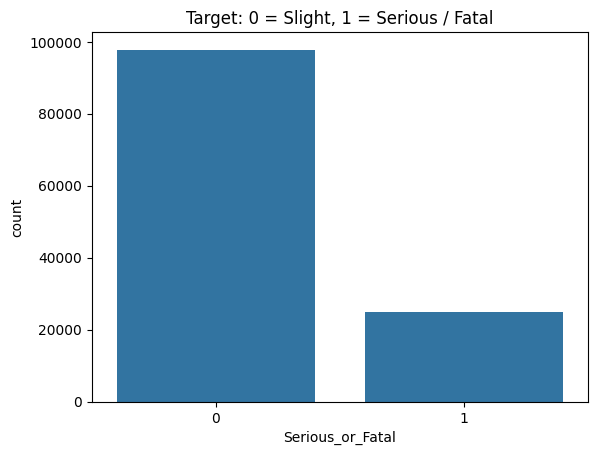

In [9]:
print(accidents["Accident_Severity"].value_counts().sort_index())
accidents["Serious_or_Fatal"] = (accidents["Accident_Severity"] <= 2).astype(int)
print(accidents["Serious_or_Fatal"].value_counts(normalize=True).round(3))
sns.countplot(x="Serious_or_Fatal", data=accidents)
plt.title("Target: 0 = Slight, 1 = Serious / Fatal")
plt.savefig("results/target_distribution.png", bbox_inches="tight")
plt.show()

The classes are imbalanced (80% / 20%), so **accuracy is not a good metric** (a model that always says *Slight* gets 80%). PR-AUC, ROC-AUC, F1 and Balanced Accuracy are used instead, and `class_weight` / a tuned threshold are used to deal with the imbalance. The split is **stratified**.

## 5. Data cleaning

In [10]:
# -1 = missing / out of range in the whole dataset
accidents = accidents.replace(-1, np.nan)
vehicles = vehicles.replace(-1, np.nan)
casualties = casualties.replace(-1, np.nan)
print("Missing values in Accidents:")
m = accidents.isnull().sum()
print(m[m > 0])

Missing values in Accidents:
Location_Easting_OSGR                             55
Location_Northing_OSGR                            55
Longitude                                         55
Latitude                                          55
Time                                              13
Junction_Detail                                  772
Junction_Control                               54842
2nd_Road_Class                                 52211
2nd_Road_Number                                  204
Pedestrian_Crossing-Human_Control               3173
Pedestrian_Crossing-Physical_Facilities         2850
Weather_Conditions                                19
Road_Surface_Conditions                         1223
Special_Conditions_at_Site                      1524
Carriageway_Hazards                             1325
Urban_or_Rural_Area                                1
Did_Police_Officer_Attend_Scene_of_Accident        2
LSOA_of_Accident_Location                       6445
dtype: int64


In [11]:
# Time and Date -> hour and month (Day_of_Week already exists)
accidents["Hour"] = pd.to_datetime(accidents["Time"], format="%H:%M", errors="coerce").dt.hour
accidents["Month"] = pd.to_datetime(accidents["Date"], format="%d/%m/%Y", errors="coerce").dt.month
accidents["Is_Weekend"] = accidents["Day_of_Week"].isin([1, 7]).astype(int)   # 1 = Sunday, 7 = Saturday
print(accidents[["Hour", "Month", "Is_Weekend"]].describe().loc[["count", "min", "max"]])

           Hour     Month  Is_Weekend
count  122622.0  122635.0    122635.0
min         0.0       1.0         0.0
max        23.0      12.0         1.0


## 6. Features from the Vehicles table
One accident can have several vehicles, so the vehicles are **summarised to one row per accident** and joined to the accidents.
Only information that exists **at the time of the accident** is used (type of vehicles, ages).

In [12]:
# Vehicle_Type codes: 1 pedal cycle, 2-5/23/97 motorcycles, 10-11 bus/coach, 20-21/98 heavy goods vehicles
vehicles["is_motorcycle"] = vehicles["Vehicle_Type"].isin([2, 3, 4, 5, 23, 97]).astype(int)
vehicles["is_pedal_cycle"] = (vehicles["Vehicle_Type"] == 1).astype(int)
vehicles["is_bus"] = vehicles["Vehicle_Type"].isin([10, 11]).astype(int)
vehicles["is_heavy"] = vehicles["Vehicle_Type"].isin([20, 21, 98]).astype(int)

veh_summary = vehicles.groupby("Accident_Index").agg(
    Has_Motorcycle=("is_motorcycle", "max"),
    Has_Pedal_Cycle=("is_pedal_cycle", "max"),
    Has_Bus=("is_bus", "max"),
    Has_Heavy_Vehicle=("is_heavy", "max"),
    Min_Driver_Age=("Age_of_Driver", "min"),
    Max_Driver_Age=("Age_of_Driver", "max"),
    Max_Vehicle_Age=("Age_of_Vehicle", "max"),
).reset_index()
veh_summary.head()

,Accident_Index,Has_Motorcycle,Has_Pedal_Cycle,Has_Bus,Has_Heavy_Vehicle,Min_Driver_Age,Max_Driver_Age,Max_Vehicle_Age
0,2018010080971,0,0,0,0,32.0,48.0,6.0
1,2018010080973,0,0,0,0,NaN,NaN,NaN
2,2018010080974,0,0,0,0,21.0,40.0,6.0
3,2018010080981,0,0,0,0,27.0,30.0,1.0
4,2018010080982,0,0,0,0,43.0,55.0,1.0


## 7. Casualties table (EDA only — NOT used as model features)
The injuries are the **result** of the accident. `Accident_Severity` is defined from the most serious injury, so using `Casualty_Severity` or `Number_of_Casualties` would be **data leakage** (the model would see the answer). The Casualties table is used here to understand the data only.

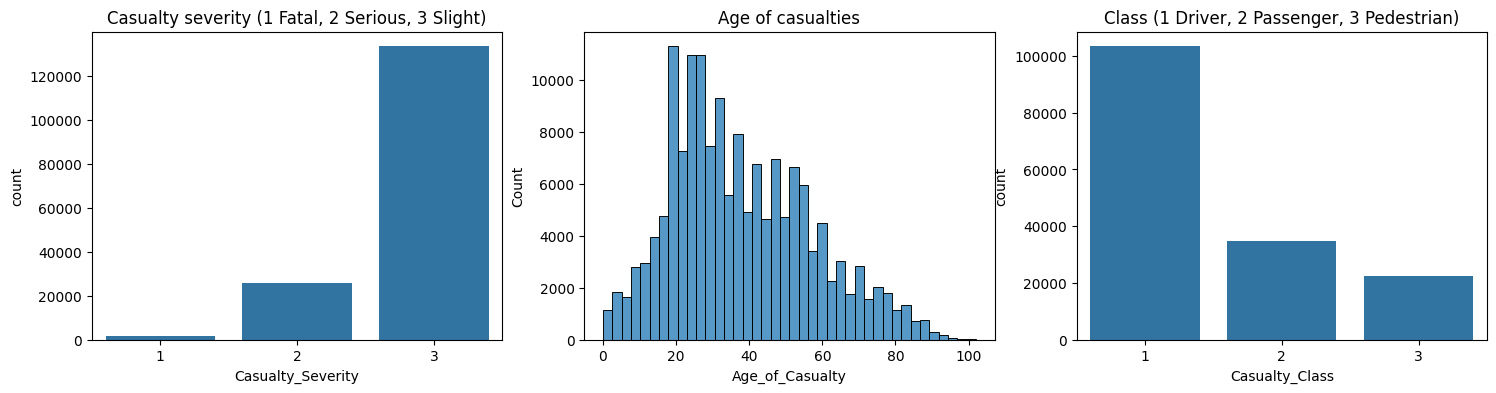

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4))
sns.countplot(x="Casualty_Severity", data=casualties, ax=axes[0]); axes[0].set_title("Casualty severity (1 Fatal, 2 Serious, 3 Slight)")
sns.histplot(casualties["Age_of_Casualty"].dropna(), bins=40, ax=axes[1]); axes[1].set_title("Age of casualties")
sns.countplot(x="Casualty_Class", data=casualties, ax=axes[2]); axes[2].set_title("Class (1 Driver, 2 Passenger, 3 Pedestrian)")
plt.savefig("results/eda_casualties.png", bbox_inches="tight")
plt.show()

In [14]:
# severity of an accident = worst injury: check that the casualty table really contains the answer (this is why it is not used)
worst = casualties.groupby("Accident_Index")["Casualty_Severity"].min()
check = accidents.set_index("Accident_Index")["Accident_Severity"].reindex(worst.index)
print("Accident severity == worst casualty severity in", round((worst == check).mean() * 100, 1), "% of the accidents  -> leakage if used")

Accident severity == worst casualty severity in 100.0 % of the accidents  -> leakage if used


## 8. Merge and choose the columns

In [15]:
df = accidents.merge(veh_summary, on="Accident_Index", how="left")
print(df.shape)

# columns dropped and why
drop_cols = [
    "Accident_Index",                      # id
    "Accident_Severity", "Date", "Time",   # target / replaced by Hour, Month
    "Number_of_Casualties",                # known only after the accident -> leakage
    "Did_Police_Officer_Attend_Scene_of_Accident",   # decided after the accident (serious ones get a police visit)
    "Location_Easting_OSGR", "Location_Northing_OSGR",   # same information as Latitude / Longitude
    "Local_Authority_(Highway)", "LSOA_of_Accident_Location",   # too many different values (text codes)
    "Local_Authority_(District)",          # about 400 values
    "1st_Road_Number", "2nd_Road_Number",  # road ids, not a real number
]
df = df.drop(columns=drop_cols)
print(df.shape)
df.columns.tolist()

(122635, 43)
(122635, 30)


['Longitude',
 'Latitude',
 'Police_Force',
 'Number_of_Vehicles',
 'Day_of_Week',
 '1st_Road_Class',
 'Road_Type',
 'Speed_limit',
 'Junction_Detail',
 'Junction_Control',
 '2nd_Road_Class',
 'Pedestrian_Crossing-Human_Control',
 'Pedestrian_Crossing-Physical_Facilities',
 'Light_Conditions',
 'Weather_Conditions',
 'Road_Surface_Conditions',
 'Special_Conditions_at_Site',
 'Carriageway_Hazards',
 'Urban_or_Rural_Area',
 'Serious_or_Fatal',
 'Hour',
 'Month',
 'Is_Weekend',
 'Has_Motorcycle',
 'Has_Pedal_Cycle',
 'Has_Bus',
 'Has_Heavy_Vehicle',
 'Min_Driver_Age',
 'Max_Driver_Age',
 'Max_Vehicle_Age']

## 9. Duplicates, missing values and outliers
- **Duplicates:** checked again after the merge (above: none in the tables).
- **Missing values:** will be filled **inside the pipeline** (median for numbers, most frequent for categories), learned from the train data only.
- **Outliers (IQR rule):** checked below.

In [16]:
print("Duplicated rows:", df.duplicated().sum())
miss = (df.isnull().mean() * 100).round(2)
print(miss[miss > 0].sort_values(ascending=False))

Duplicated rows: 5
Junction_Control                           44.72
2nd_Road_Class                             42.57
Max_Vehicle_Age                            13.42
Min_Driver_Age                              4.62
Max_Driver_Age                              4.62
Pedestrian_Crossing-Human_Control           2.59
Pedestrian_Crossing-Physical_Facilities     2.32
Special_Conditions_at_Site                  1.24
Carriageway_Hazards                         1.08
Road_Surface_Conditions                     1.00
Junction_Detail                             0.63
Longitude                                   0.04
Latitude                                    0.04
Weather_Conditions                          0.02
Hour                                        0.01
dtype: float64


In [17]:
for col in ["Speed_limit", "Number_of_Vehicles", "Min_Driver_Age", "Max_Driver_Age", "Max_Vehicle_Age"]:
    q1, q3 = df[col].quantile(0.25), df[col].quantile(0.75)
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_out = ((df[col] < low) | (df[col] > high)).sum()
    print(f"{col}: {n_out} outliers ({n_out / df[col].notna().sum() * 100:.1f}%), valid range {low:.0f} to {high:.0f}, max = {df[col].max():.0f}")

Speed_limit: 23213 outliers (18.9%), valid range 15 to 55, max = 70
Number_of_Vehicles: 2978 outliers (2.4%), valid range -0 to 4, max = 24
Min_Driver_Age: 2133 outliers (1.8%), valid range -6 to 74, max = 100
Max_Driver_Age: 62 outliers (0.1%), valid range -4 to 96, max = 101
Max_Vehicle_Age: 688 outliers (0.6%), valid range -7 to 25, max = 84


**Decision:** the outliers are **kept**. They are real cases (accidents with many vehicles, very old drivers or cars, 70 mph roads), and the rare big accidents are exactly the interesting ones. Tree models are not sensitive to them, and the scaler is used for the linear models. No impossible values exist (the -1 codes were already converted to missing).

## 10. EDA — what is related to a serious accident?

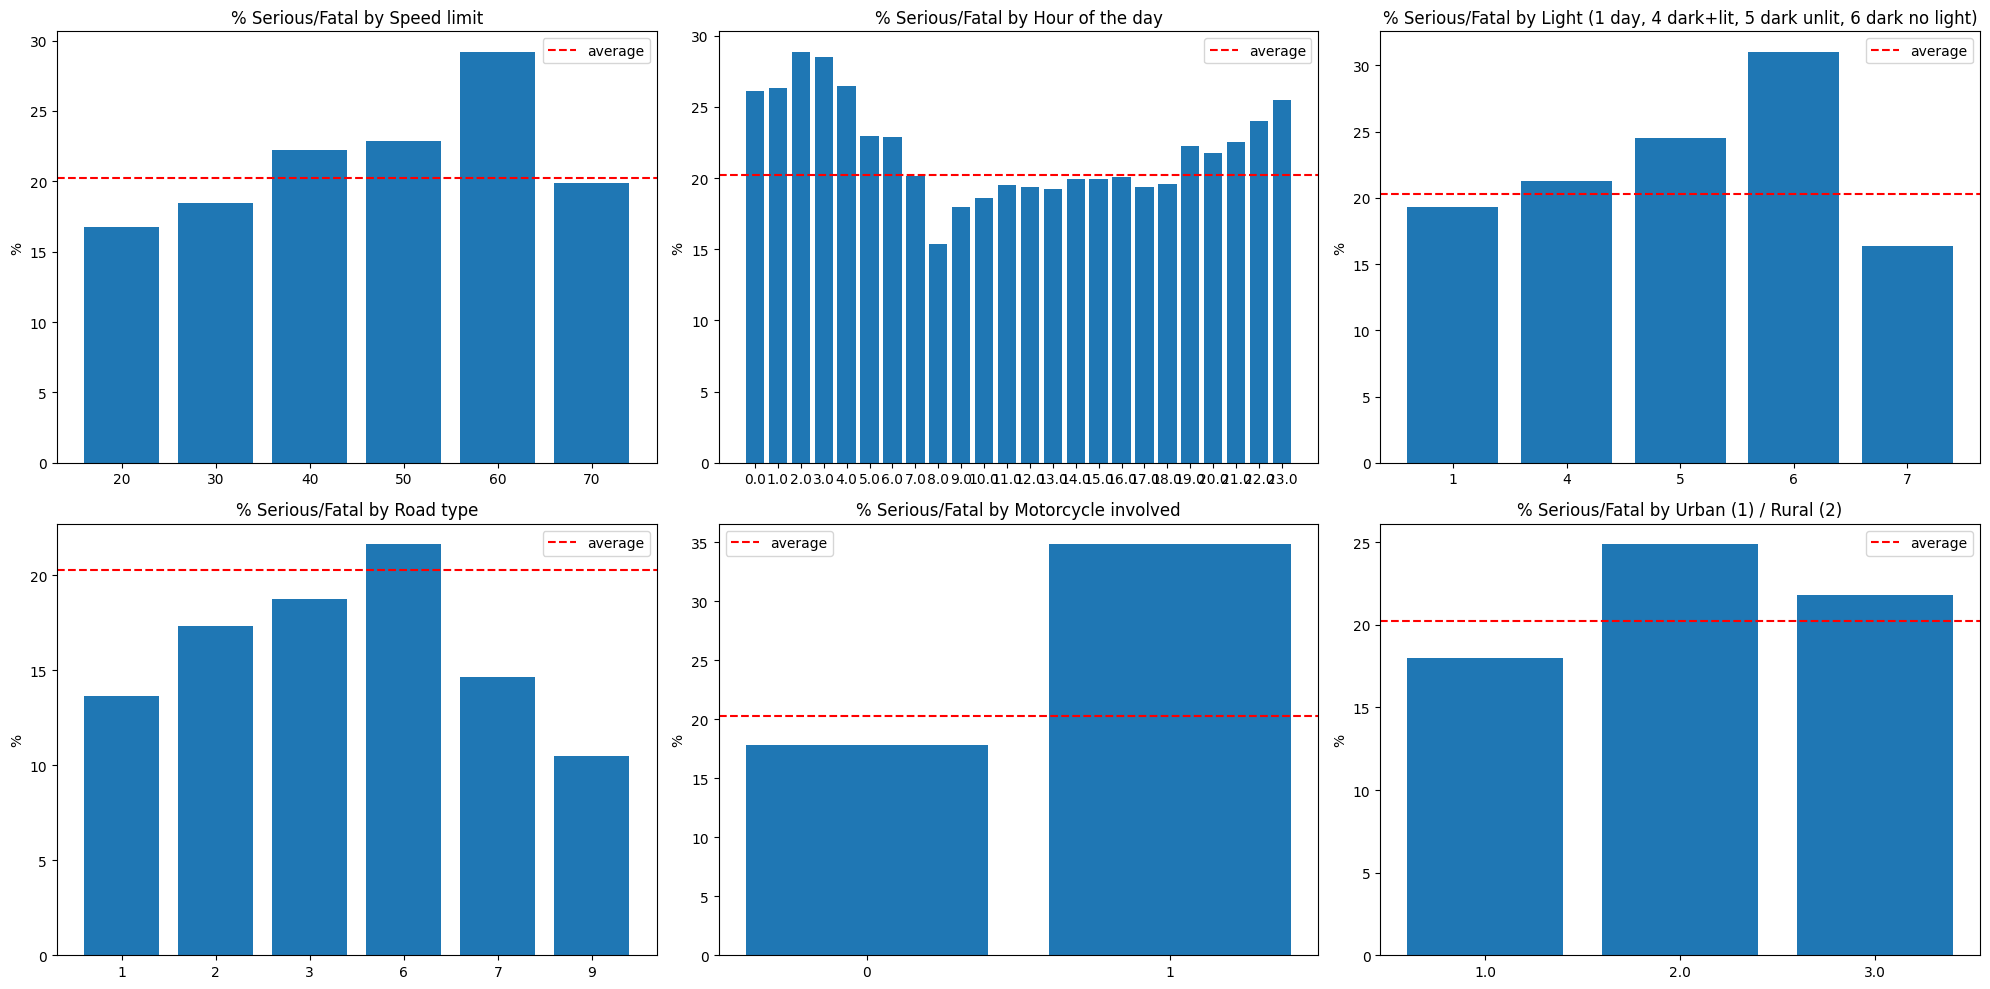

In [18]:
fig, axes = plt.subplots(2, 3, figsize=(20, 10))
for ax, col, title in zip(axes.ravel(),
        ["Speed_limit", "Hour", "Light_Conditions", "Road_Type", "Has_Motorcycle", "Urban_or_Rural_Area"],
        ["Speed limit", "Hour of the day", "Light (1 day, 4 dark+lit, 5 dark unlit, 6 dark no light)", "Road type", "Motorcycle involved", "Urban (1) / Rural (2)"]):
    rate = df.groupby(col)["Serious_or_Fatal"].mean() * 100
    ax.bar(rate.index.astype(str), rate.values)
    ax.axhline(df["Serious_or_Fatal"].mean() * 100, color="red", linestyle="--", label="average")
    ax.set_title("% Serious/Fatal by " + title); ax.set_ylabel("%"); ax.legend()
plt.tight_layout()
plt.savefig("results/eda_severity_rates.png", bbox_inches="tight")
plt.show()

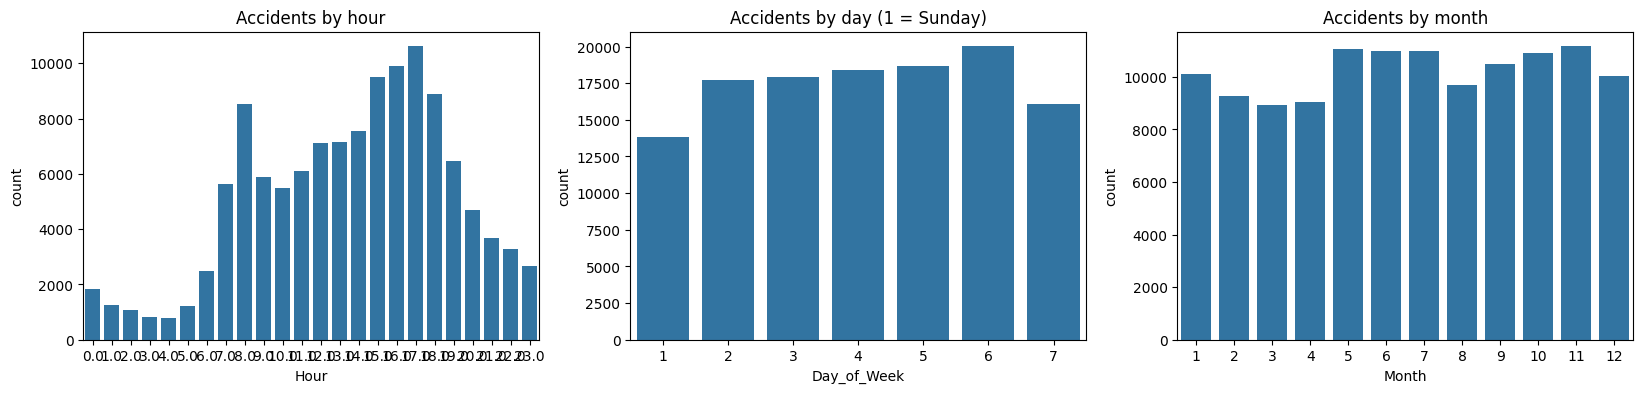

In [19]:
fig, axes = plt.subplots(1, 3, figsize=(20, 4))
sns.countplot(x="Hour", data=df, ax=axes[0]); axes[0].set_title("Accidents by hour")
sns.countplot(x="Day_of_Week", data=df, ax=axes[1]); axes[1].set_title("Accidents by day (1 = Sunday)")
sns.countplot(x="Month", data=df, ax=axes[2]); axes[2].set_title("Accidents by month")
plt.savefig("results/eda_time.png", bbox_inches="tight")
plt.show()

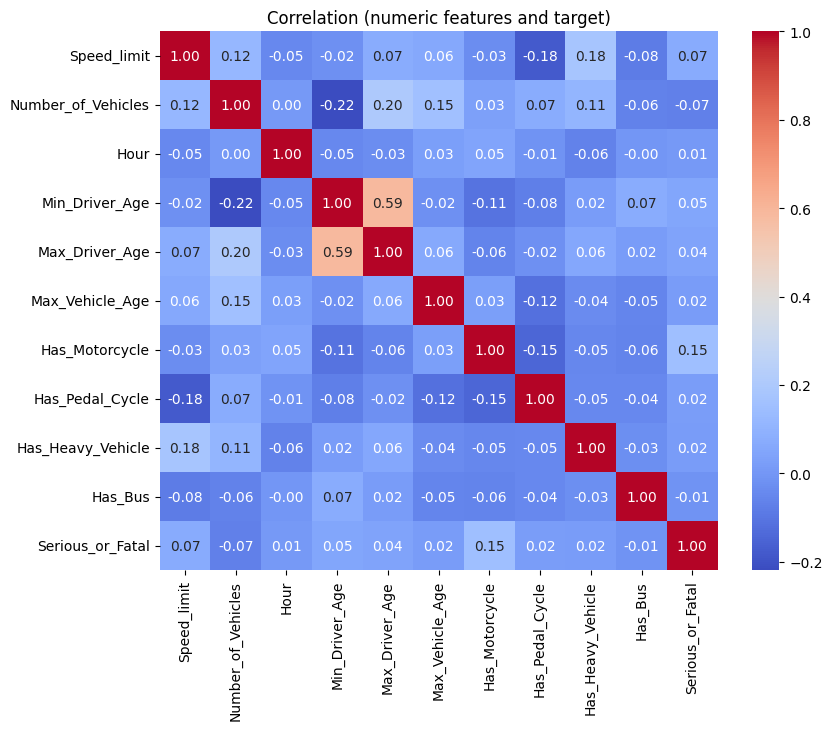

In [20]:
num_for_corr = ["Speed_limit", "Number_of_Vehicles", "Hour", "Min_Driver_Age", "Max_Driver_Age", "Max_Vehicle_Age",
                "Has_Motorcycle", "Has_Pedal_Cycle", "Has_Heavy_Vehicle", "Has_Bus", "Serious_or_Fatal"]
plt.figure(figsize=(9, 7))
sns.heatmap(df[num_for_corr].corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation (numeric features and target)")
plt.savefig("results/eda_correlation.png", bbox_inches="tight")
plt.show()

**What the EDA shows (real numbers from the data):**
- The share of serious/fatal accidents is about **20%** overall. It rises with the **speed limit** from about 17% (20 mph) to 29% (60 mph); the 70 mph roads (mostly motorways with many vehicles in a line) are lower (about 20%).
- Accidents with a **motorcycle** are serious in about **39%** of the cases and with a **pedal cycle** in about **23%** (unprotected riders), against 20% on average.
- **Rural** roads (25%) are worse than urban ones (18%), and **darkness with no street lighting** (31%) is worse than daylight (19%).
- The **night hours** (22:00 to 04:00) have a higher serious rate (about 23-29%) than the day hours (15-20%), although there are far fewer accidents at night.
- The correlations are weak and non-linear, which suggests tree-based models will work better than linear ones.

## 11. Features (X) and target (y), then Train / Test split

In [21]:
y = df["Serious_or_Fatal"]
X = df.drop(columns="Serious_or_Fatal")

# numeric columns (real numbers) vs categorical columns (codes)
num_cols = ["Number_of_Vehicles", "Speed_limit", "Latitude", "Longitude", "Hour", "Month", "Is_Weekend",
            "Min_Driver_Age", "Max_Driver_Age", "Max_Vehicle_Age",
            "Has_Motorcycle", "Has_Pedal_Cycle", "Has_Bus", "Has_Heavy_Vehicle"]
cat_cols = [c for c in X.columns if c not in num_cols]
print("Numeric    :", num_cols)
print("Categorical:", cat_cols)

# split BEFORE any fitting (imputing / scaling / encoding are learned from the train data only inside the pipeline)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
print(X_train.shape, X_test.shape)
print("Serious/Fatal rate  train:", y_train.mean().round(4), " test:", y_test.mean().round(4))

Numeric    : ['Number_of_Vehicles', 'Speed_limit', 'Latitude', 'Longitude', 'Hour', 'Month', 'Is_Weekend', 'Min_Driver_Age', 'Max_Driver_Age', 'Max_Vehicle_Age', 'Has_Motorcycle', 'Has_Pedal_Cycle', 'Has_Bus', 'Has_Heavy_Vehicle']
Categorical: ['Police_Force', 'Day_of_Week', '1st_Road_Class', 'Road_Type', 'Junction_Detail', 'Junction_Control', '2nd_Road_Class', 'Pedestrian_Crossing-Human_Control', 'Pedestrian_Crossing-Physical_Facilities', 'Light_Conditions', 'Weather_Conditions', 'Road_Surface_Conditions', 'Special_Conditions_at_Site', 'Carriageway_Hazards', 'Urban_or_Rural_Area']
(98108, 29) (24527, 29)
Serious/Fatal rate  train: 0.2025  test: 0.2025


## 12. Preprocessing pipeline (ColumnTransformer)
- **Numbers:** missing → median, then StandardScaler.
- **Categories (codes):** missing → most frequent, then OneHotEncoder (unknown categories ignored, rare ones grouped).

Everything is inside a `Pipeline`, so when a model is trained or cross-validated, the imputer / scaler / encoder learn **only from the training part** → no data leakage. The same pipeline is saved and used by the app.

In [22]:
def make_preprocessor():
    num_pipe = Pipeline([("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler())])
    cat_pipe = Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),
                         ("onehot", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=50, sparse_output=False))])
    return ColumnTransformer([("num", num_pipe, num_cols), ("cat", cat_pipe, cat_cols)])

def make_pipeline(model):
    return Pipeline([("prep", make_preprocessor()), ("model", model)])

## 13. All the models
All the classification models of the track are compared. The imbalance is handled with `class_weight="balanced"` (or `scale_pos_weight`) where the model supports it. Models without class weights (KNN, Bagging, AdaBoost) are compared too, and the decision threshold is tuned later.

In [23]:
pos_weight = (y_train == 0).sum() / (y_train == 1).sum()
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, class_weight="balanced"),
    "SVM (linear)": LinearSVC(C=0.1, class_weight="balanced"),
    "Naive Bayes": GaussianNB(),
    "KNN": KNeighborsClassifier(n_neighbors=25, n_jobs=-1),
    "Decision Tree": DecisionTreeClassifier(max_depth=8, class_weight="balanced", random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(n_estimators=100, min_samples_leaf=5, max_depth=14, class_weight="balanced", n_jobs=-1, random_state=RANDOM_STATE),
    "ExtraTrees": ExtraTreesClassifier(n_estimators=100, min_samples_leaf=5, max_depth=14, class_weight="balanced", n_jobs=-1, random_state=RANDOM_STATE),
    "Bagging": BaggingClassifier(n_estimators=15, n_jobs=-1, random_state=RANDOM_STATE),
    "AdaBoost": AdaBoostClassifier(n_estimators=50, random_state=RANDOM_STATE),
    "Gradient Boosting": GradientBoostingClassifier(n_estimators=60, random_state=RANDOM_STATE),
    "HistGradientBoosting": HistGradientBoostingClassifier(class_weight="balanced", random_state=RANDOM_STATE),
    "XGBoost": XGBClassifier(n_estimators=150, max_depth=4, learning_rate=0.1, scale_pos_weight=pos_weight, eval_metric="logloss", n_jobs=-1, random_state=RANDOM_STATE),
    "LightGBM": LGBMClassifier(n_estimators=150, learning_rate=0.1, class_weight="balanced", n_jobs=-1, random_state=RANDOM_STATE, verbose=-1),
    "CatBoost": CatBoostClassifier(iterations=150, learning_rate=0.1, auto_class_weights="Balanced", verbose=0, random_seed=RANDOM_STATE),
}
print(len(models), "models")

14 models


## 14. All the models: Accuracy, Precision, Recall, F1 (Train vs Test)
Every model is trained once and evaluated on **Train** and **Test** with the default decision rule of the model (threshold 0.5), the same table as in the other tasks. To save time the models are trained on a **stratified 50,000-row part of the train data**, the Train scores are computed on 10,000 of those rows, and the Test scores on the **whole test set**.

**This table is only to see how every model behaves (and to spot overfitting: Train much higher than Test). The model is NOT chosen from the test set:** the choice is made by cross-validation on the train data in the next sections.

In [24]:
TABLE_N = min(50000, len(X_train))
X_tab, _, y_tab, _ = train_test_split(X_train, y_train, train_size=TABLE_N, stratify=y_train, random_state=RANDOM_STATE)
X_tr_eval, y_tr_eval = X_tab.iloc[:10000], y_tab.iloc[:10000]

def get_score(pipe, X):
    # probability if the model has it, otherwise the decision function (SVM) -> only used for ROC-AUC / PR-AUC
    return pipe.predict_proba(X)[:, 1] if hasattr(pipe, "predict_proba") else pipe.decision_function(X)

def scores(pipe, X, y):
    pred = pipe.predict(X)
    s = get_score(pipe, X)
    return {"Accuracy": accuracy_score(y, pred), "Precision": precision_score(y, pred, zero_division=0),
            "Recall": recall_score(y, pred), "F1": f1_score(y, pred), "Balanced Acc": balanced_accuracy_score(y, pred),
            "ROC-AUC": roc_auc_score(y, s), "PR-AUC": average_precision_score(y, s)}

all_rows = {}
for name, model in models.items():
    t0 = time.time()
    pipe = make_pipeline(model).fit(X_tab, y_tab)
    tr, te = scores(pipe, X_tr_eval, y_tr_eval), scores(pipe, X_test, y_test)
    all_rows[name] = {**{k + " Train": v for k, v in tr.items()}, **{k + " Test": v for k, v in te.items()}}
    print(f"{name:22s} Accuracy test={te['Accuracy']:.3f}  F1 test={te['F1']:.3f}  ({time.time() - t0:.0f}s)")

all_df = pd.DataFrame(all_rows).T.sort_values("PR-AUC Test", ascending=False)
all_df.to_csv("results/all_models_train_test.csv")
all_df.round(3)

Logistic Regression    Accuracy test=0.639  F1 test=0.406  (7s)
SVM (linear)           Accuracy test=0.640  F1 test=0.404  (4s)
Naive Bayes            Accuracy test=0.663  F1 test=0.336  (1s)
KNN                    Accuracy test=0.801  F1 test=0.119  (65s)
Decision Tree          Accuracy test=0.636  F1 test=0.410  (1s)
Random Forest          Accuracy test=0.696  F1 test=0.413  (8s)
ExtraTrees             Accuracy test=0.671  F1 test=0.392  (9s)
Bagging                Accuracy test=0.783  F1 test=0.213  (20s)
AdaBoost               Accuracy test=0.799  F1 test=0.066  (10s)
Gradient Boosting      Accuracy test=0.801  F1 test=0.081  (25s)
HistGradientBoosting   Accuracy test=0.640  F1 test=0.426  (8s)
XGBoost                Accuracy test=0.647  F1 test=0.428  (3s)
LightGBM               Accuracy test=0.654  F1 test=0.430  (2s)
CatBoost               Accuracy test=0.649  F1 test=0.428  (5s)


,Accuracy Train,Precision Train,Recall Train,F1 Train,Balanced Acc Train,ROC-AUC Train,PR-AUC Train,Accuracy Test,Precision Test,Recall Test,F1 Test,Balanced Acc Test,ROC-AUC Test,PR-AUC Test
XGBoost,0.673,0.356,0.709,0.474,0.686,0.756,0.459,0.647,0.318,0.651,0.428,0.648,0.711,0.386
HistGradientBoosting,0.678,0.367,0.751,0.493,0.705,0.775,0.479,0.640,0.315,0.661,0.426,0.648,0.710,0.384
CatBoost,0.674,0.356,0.700,0.472,0.683,0.756,0.456,0.649,0.319,0.649,0.428,0.649,0.710,0.383
LightGBM,0.709,0.398,0.775,0.526,0.733,0.813,0.540,0.654,0.323,0.644,0.430,0.650,0.709,0.382
Random Forest,0.766,0.460,0.707,0.557,0.744,0.833,0.590,0.696,0.339,0.528,0.413,0.634,0.699,0.373
Gradient Boosting,0.796,0.645,0.044,0.082,0.519,0.716,0.398,0.801,0.618,0.043,0.081,0.518,0.701,0.373
ExtraTrees,0.730,0.411,0.687,0.514,0.714,0.792,0.508,0.671,0.313,0.522,0.392,0.616,0.672,0.356
Logistic Regression,0.644,0.319,0.622,0.421,0.636,0.683,0.370,0.639,0.305,0.609,0.406,0.628,0.680,0.354
SVM (linear),0.645,0.319,0.619,0.421,0.635,0.683,0.369,0.640,0.304,0.603,0.404,0.626,0.679,0.353
AdaBoost,0.794,0.575,0.035,0.066,0.514,0.690,0.358,0.799,0.547,0.035,0.066,0.514,0.690,0.350


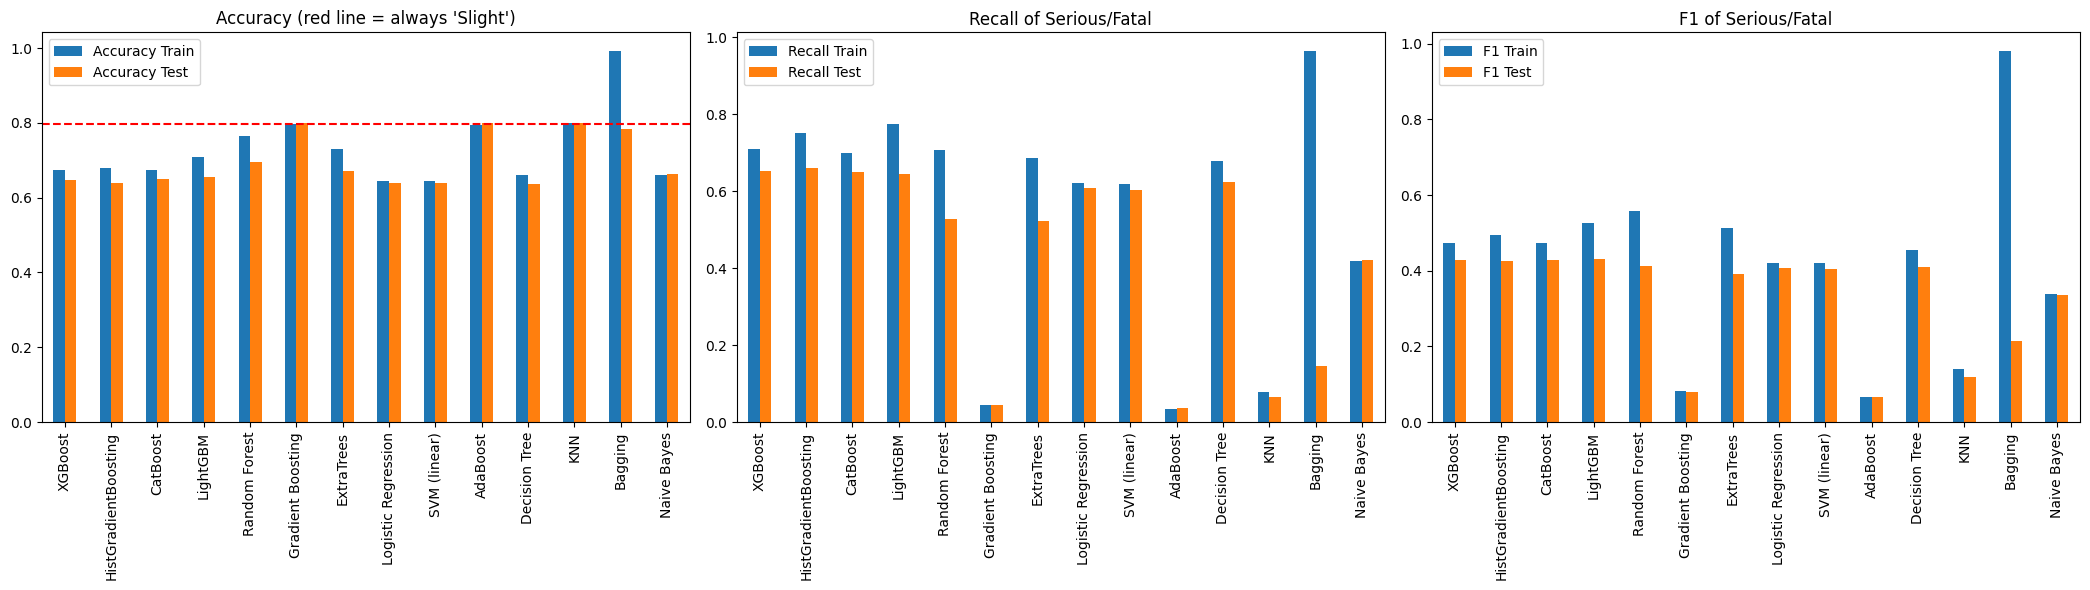

In [25]:
fig, axes = plt.subplots(1, 3, figsize=(21, 6))
all_df[["Accuracy Train", "Accuracy Test"]].plot.bar(ax=axes[0]); axes[0].axhline(1 - y_test.mean(), color="red", linestyle="--"); axes[0].set_title("Accuracy (red line = always 'Slight')")
all_df[["Recall Train", "Recall Test"]].plot.bar(ax=axes[1]); axes[1].set_title("Recall of Serious/Fatal")
all_df[["F1 Train", "F1 Test"]].plot.bar(ax=axes[2]); axes[2].set_title("F1 of Serious/Fatal")
plt.tight_layout()
plt.savefig("results/all_models_train_test.png", bbox_inches="tight")
plt.show()

**How to read it:** the **Accuracy** of models with `class_weight="balanced"` is *lower* than the 80% of a model that always says *Slight* — this is expected: they give up some accuracy to find more serious accidents (higher **Recall**). Models without class weights (KNN, Bagging, AdaBoost, Gradient Boosting, XGBoost...) have a higher accuracy but a very low recall, so they miss most serious accidents. A big gap between Train and Test (Decision Tree, Random Forest, ExtraTrees, Bagging, KNN) means **overfitting**. Naive Bayes is weak because its independence assumption does not fit the one-hot features. So **Accuracy is not used to choose the model**; PR-AUC, ROC-AUC and Recall / F1 of the serious class are.

## 15. Model comparison with Cross-Validation (train data only)
3-fold **StratifiedKFold** on the training set (the test set is not touched). To keep the run time reasonable (the notebook runs on a free Colab), the comparison uses a **stratified sample of 15,000 training rows**; the final model is trained on all the training data.
The main metric is **PR-AUC** (Average Precision), because it is the right metric for the rare class. ROC-AUC and F1 are shown too.

In [26]:
SAMPLE = min(15000, int(len(X_train) * 0.8))
X_cv, _, y_cv, _ = train_test_split(X_train, y_train, train_size=SAMPLE, stratify=y_train, random_state=RANDOM_STATE)
skf = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)
scoring = {"pr_auc": "average_precision", "roc_auc": "roc_auc", "f1": "f1"}

rows = {}
for name, model in models.items():
    t0 = time.time()
    cv = cross_validate(make_pipeline(model), X_cv, y_cv, cv=skf, scoring=scoring, n_jobs=1)
    rows[name] = {"CV PR-AUC": cv["test_pr_auc"].mean(), "CV ROC-AUC": cv["test_roc_auc"].mean(),
                  "CV F1 (thr 0.5)": cv["test_f1"].mean(), "CV PR-AUC std": cv["test_pr_auc"].std(),
                  "Time (s)": time.time() - t0}
    print(f"{name:22s} PR-AUC={rows[name]['CV PR-AUC']:.4f}  ROC-AUC={rows[name]['CV ROC-AUC']:.4f}  ({rows[name]['Time (s)']:.0f}s)")

cv_df = pd.DataFrame(rows).T.sort_values("CV PR-AUC", ascending=False)
cv_df.to_csv("results/model_comparison_cv.csv")
cv_df.round(4)

Logistic Regression    PR-AUC=0.3428  ROC-AUC=0.6687  (3s)
SVM (linear)           PR-AUC=0.3427  ROC-AUC=0.6688  (1s)
Naive Bayes            PR-AUC=0.2602  ROC-AUC=0.5869  (0s)
KNN                    PR-AUC=0.2999  ROC-AUC=0.6423  (5s)
Decision Tree          PR-AUC=0.3026  ROC-AUC=0.6342  (1s)
Random Forest          PR-AUC=0.3556  ROC-AUC=0.6883  (5s)
ExtraTrees             PR-AUC=0.3325  ROC-AUC=0.6595  (4s)
Bagging                PR-AUC=0.2951  ROC-AUC=0.6424  (8s)
AdaBoost               PR-AUC=0.3385  ROC-AUC=0.6842  (4s)
Gradient Boosting      PR-AUC=0.3562  ROC-AUC=0.6975  (9s)
HistGradientBoosting   PR-AUC=0.3482  ROC-AUC=0.6843  (6s)
XGBoost                PR-AUC=0.3515  ROC-AUC=0.6861  (2s)
LightGBM               PR-AUC=0.3444  ROC-AUC=0.6769  (2s)
CatBoost               PR-AUC=0.3574  ROC-AUC=0.6908  (5s)


,CV PR-AUC,CV ROC-AUC,CV F1 (thr 0.5),CV PR-AUC std,Time (s)
CatBoost,0.3574,0.6908,0.4130,0.0033,4.9408
Gradient Boosting,0.3562,0.6975,0.0876,0.0033,9.4449
Random Forest,0.3556,0.6883,0.3860,0.0066,4.7916
XGBoost,0.3515,0.6861,0.4095,0.0088,1.7747
HistGradientBoosting,0.3482,0.6843,0.4032,0.0069,5.8622
LightGBM,0.3444,0.6769,0.3939,0.0070,1.5713
Logistic Regression,0.3428,0.6687,0.4010,0.0037,2.7993
SVM (linear),0.3427,0.6688,0.4009,0.0047,0.8633
AdaBoost,0.3385,0.6842,0.0601,0.0044,4.0589
ExtraTrees,0.3325,0.6595,0.3806,0.0076,3.8009


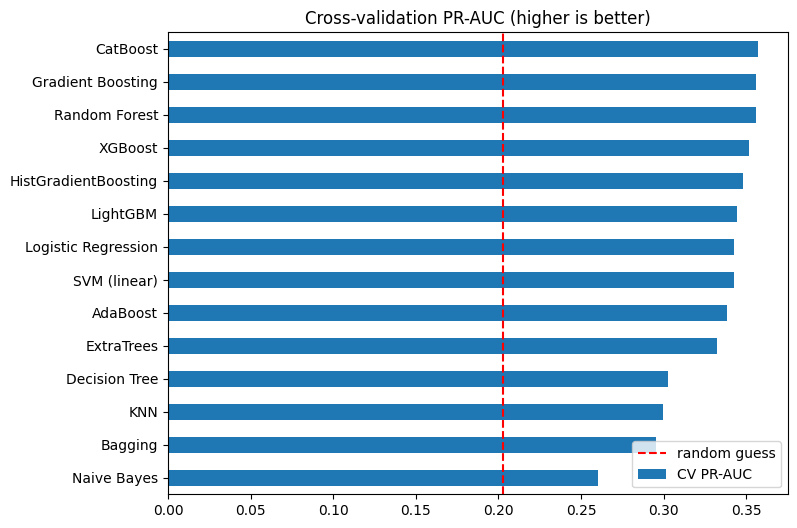

In [27]:
cv_df["CV PR-AUC"].sort_values().plot.barh(figsize=(8, 6))
plt.axvline(y_train.mean(), color="red", linestyle="--", label="random guess")
plt.title("Cross-validation PR-AUC (higher is better)")
plt.legend()
plt.savefig("results/model_comparison_cv.png", bbox_inches="tight")
plt.show()

**Reading the table:** the gradient boosting family (LightGBM, HistGradientBoosting, CatBoost, XGBoost, Gradient Boosting) is expected to lead, because the relation between the road conditions and the severity is non-linear and made of many interactions. Logistic Regression is a good baseline. Models with low scores (KNN, Decision Tree, AdaBoost) are **not selected**: KNN suffers from the many one-hot columns, a single shallow tree is too simple, and AdaBoost has no class weights.

## 16. GridSearchCV on the best 3 models
The 3 models with the best CV PR-AUC are tuned with `GridSearchCV` (same 3-fold CV, same 15,000-row sample, scoring = PR-AUC). The grids are small on purpose; the parameters are explained below the table.

In [28]:
top3 = list(cv_df.index[:3])
print("Models to tune:", top3)

grids = {
    "LightGBM": {"model__n_estimators": [150, 300], "model__learning_rate": [0.05, 0.1], "model__num_leaves": [15]},
    "HistGradientBoosting": {"model__max_iter": [100, 200], "model__learning_rate": [0.05, 0.1], "model__max_depth": [6]},
    "CatBoost": {"model__iterations": [150, 300], "model__learning_rate": [0.05, 0.1], "model__depth": [6]},
    "XGBoost": {"model__n_estimators": [150, 300], "model__learning_rate": [0.05, 0.1], "model__max_depth": [4]},
    "Gradient Boosting": {"model__n_estimators": [60, 120], "model__learning_rate": [0.05, 0.1], "model__max_depth": [3]},
    "Random Forest": {"model__n_estimators": [100, 200], "model__min_samples_leaf": [5, 20]},
    "ExtraTrees": {"model__n_estimators": [100, 200], "model__min_samples_leaf": [5, 20]},
    "Naive Bayes": {"model__var_smoothing": [1e-9, 1e-7, 1e-5]},
    "Logistic Regression": {"model__C": [0.01, 0.1, 1]},
    "SVM (linear)": {"model__C": [0.01, 0.1, 1]},
    "Bagging": {"model__n_estimators": [30, 60]},
    "AdaBoost": {"model__n_estimators": [100, 200], "model__learning_rate": [0.5, 1.0]},
    "KNN": {"model__n_neighbors": [15, 25, 50]},
    "Decision Tree": {"model__max_depth": [6, 8, 12]},
}

tuned, tuning_rows = {}, {}
for name in top3:
    gs = GridSearchCV(make_pipeline(models[name]), grids[name], scoring="average_precision", cv=skf, n_jobs=1, refit=True)
    gs.fit(X_cv, y_cv)
    tuned[name] = gs
    tuning_rows[name] = {"Before tuning (CV PR-AUC)": cv_df.loc[name, "CV PR-AUC"], "After tuning (best_score_)": gs.best_score_,
                         "best_params_": {k.replace("model__", ""): v for k, v in gs.best_params_.items()}}
    print(name); print("  best_params_:", tuning_rows[name]["best_params_"]); print("  best_score_ :", round(gs.best_score_, 4))

tuning_df = pd.DataFrame(tuning_rows).T
tuning_df.to_csv("results/gridsearch_top3.csv")
tuning_df

Models to tune: ['CatBoost', 'Gradient Boosting', 'Random Forest']
CatBoost
  best_params_: {'depth': 6, 'iterations': 150, 'learning_rate': 0.05}
  best_score_ : 0.358
Gradient Boosting
  best_params_: {'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 120}
  best_score_ : 0.3569
Random Forest
  best_params_: {'min_samples_leaf': 5, 'n_estimators': 100}
  best_score_ : 0.3556


,Before tuning (CV PR-AUC),After tuning (best_score_),best_params_
CatBoost,0.357387,0.358023,"{'depth': 6, 'iterations': 150, 'learning_rate..."
Gradient Boosting,0.356161,0.356923,"{'learning_rate': 0.1, 'max_depth': 3, 'n_esti..."
Random Forest,0.355626,0.355626,"{'min_samples_leaf': 5, 'n_estimators': 100}"


**Why these parameters:** `n_estimators` / `max_iter` / `iterations` = number of trees (more trees = more power but slower); `learning_rate` = size of each boosting step (small = slower but more careful); `num_leaves` / `max_depth` / `depth` = complexity of each tree (deeper = can learn interactions but can overfit). The grids are small because the improvement from tuning is usually small compared with the choice of the model family.

## 17. Final model
The model with the best `best_score_` is trained on **all the training data**. Then the **decision threshold** is chosen on **out-of-fold predictions of the training data** (not on the test set): the threshold with the best F1 for the Serious/Fatal class.

In [30]:
best_name = tuning_df["After tuning (best_score_)"].astype(float).idxmax()
best_params = tuned[best_name].best_params_
print("Best model:", best_name, tuning_rows[best_name]["best_params_"])

from sklearn.base import clone
final_pipe = make_pipeline(clone(models[best_name])).set_params(**best_params)

# threshold from out-of-fold probabilities on the train data
# (a stratified 30,000-row part of the train data is used to save time; the test set is not used)
X_thr, _, y_thr, _ = train_test_split(X_train, y_train, train_size=min(30000, int(len(X_train) * 0.8)), stratify=y_train, random_state=RANDOM_STATE)
oof = cross_val_predict(final_pipe, X_thr, y_thr, cv=StratifiedKFold(3, shuffle=True, random_state=RANDOM_STATE),
                        method="predict_proba", n_jobs=1)[:, 1]
thresholds = np.linspace(0.05, 0.95, 91)
f1s = [f1_score(y_thr, oof >= t) for t in thresholds]
threshold = float(thresholds[int(np.argmax(f1s))])
print("Threshold (max F1 on out-of-fold train predictions):", round(threshold, 2))

final_pipe.fit(X_train, y_train)

Best model: CatBoost {'depth': 6, 'iterations': 150, 'learning_rate': 0.05}
Threshold (max F1 on out-of-fold train predictions): 0.51


Pipeline(steps=[('prep',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['Number_of_Vehicles',
                                                   'Speed_limit', 'Latitude',
                                                   'Longitude', 'Hour', 'Month',
                                                   'Is_Weekend',
                                                   'Min_Driver_Age',
                                                   'Max_Driver_Age',
                                                   'Max_Vehicle_Age',
                                                   'Has_Motorcycle',
                                                   'Has_Pedal_Cycle', 'Has_Bus',
                                                   'Has_Heavy_V...
                                                   'Pedestrian_Crossing-Human_Control',
                                                   'Pedestrian_Crossing-Physical_Facilities',
                                                   'Light_Conditions',
                                                   'Weather_Conditions',
                                                   'Road_Surface_Conditions',
                                                   'Special_Conditions_at_Site',
                                                   'Carriageway_Hazards',
                                                   'Urban_or_Rural_Area'])])),
                ('model',
                 CatBoostClassifier(auto_class_weights='Balanced', depth=6, iterations=150, learning_rate=0.05, random_seed=42, verbose=0))])

## 18. Evaluation on the test set (used once)

In [31]:
proba = final_pipe.predict_proba(X_test)[:, 1]
pred = (proba >= threshold).astype(int)

metrics = {
    "model": best_name, "threshold": threshold, "best_params": tuning_rows[best_name]["best_params_"],
    "test_roc_auc": roc_auc_score(y_test, proba), "test_pr_auc": average_precision_score(y_test, proba),
    "random_pr_auc": float(y_test.mean()),
    "accuracy": accuracy_score(y_test, pred), "balanced_accuracy": balanced_accuracy_score(y_test, pred),
    "precision": precision_score(y_test, pred), "recall": recall_score(y_test, pred), "f1": f1_score(y_test, pred),
    "baseline_accuracy_always_slight": float(1 - y_test.mean()),
}
for k, v in metrics.items():
    print(f"{k:32s}", round(v, 4) if isinstance(v, float) else v)
print()
print(classification_report(y_test, pred, target_names=["Slight", "Serious/Fatal"]))

model                            CatBoost
threshold                        0.51
best_params                      {'depth': 6, 'iterations': 150, 'learning_rate': 0.05}
test_roc_auc                     0.7093
test_pr_auc                      0.3803
random_pr_auc                    0.2025
accuracy                         0.6523
balanced_accuracy                0.6468
precision                        0.3201
recall                           0.6374
f1                               0.4261
baseline_accuracy_always_slight  0.7975

               precision    recall  f1-score   support

       Slight       0.88      0.66      0.75     19560
Serious/Fatal       0.32      0.64      0.43      4967

     accuracy                           0.65     24527
    macro avg       0.60      0.65      0.59     24527
 weighted avg       0.76      0.65      0.68     24527



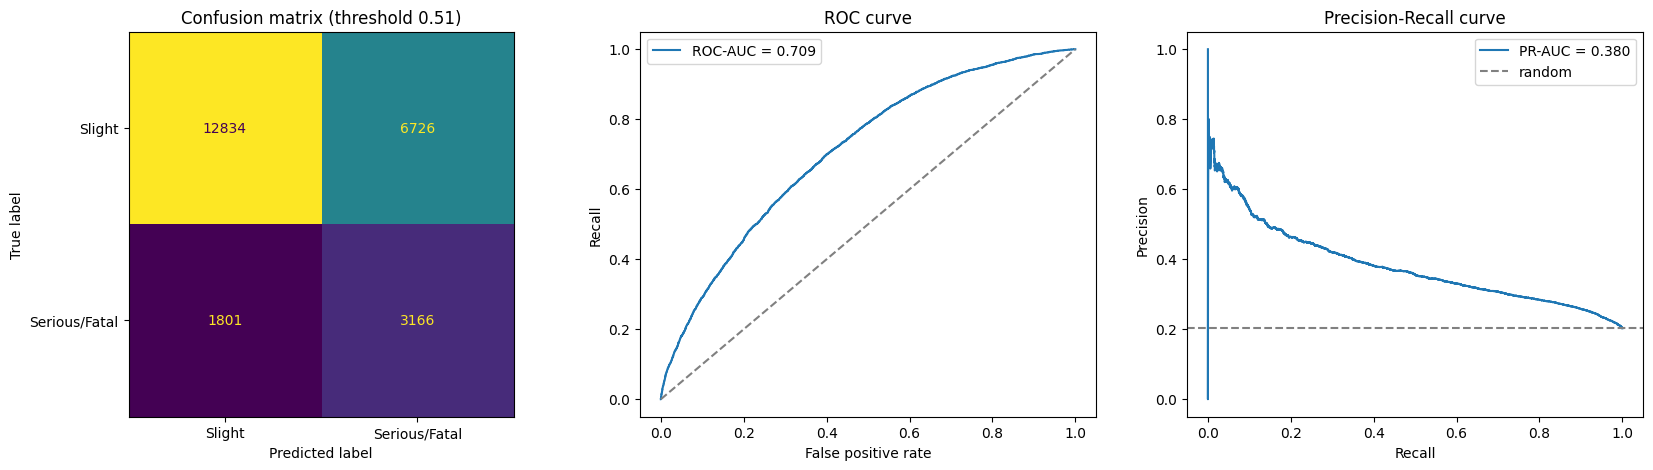

In [32]:
fig, axes = plt.subplots(1, 3, figsize=(20, 5))
ConfusionMatrixDisplay.from_predictions(y_test, pred, display_labels=["Slight", "Serious/Fatal"], ax=axes[0], colorbar=False)
axes[0].set_title("Confusion matrix (threshold %.2f)" % threshold)

fpr, tpr, _ = roc_curve(y_test, proba)
axes[1].plot(fpr, tpr, label="ROC-AUC = %.3f" % metrics["test_roc_auc"]); axes[1].plot([0, 1], [0, 1], "--", color="gray")
axes[1].set_xlabel("False positive rate"); axes[1].set_ylabel("Recall"); axes[1].set_title("ROC curve"); axes[1].legend()

prec, rec, _ = precision_recall_curve(y_test, proba)
axes[2].plot(rec, prec, label="PR-AUC = %.3f" % metrics["test_pr_auc"]); axes[2].axhline(y_test.mean(), linestyle="--", color="gray", label="random")
axes[2].set_xlabel("Recall"); axes[2].set_ylabel("Precision"); axes[2].set_title("Precision-Recall curve"); axes[2].legend()
plt.savefig("results/final_evaluation.png", bbox_inches="tight")
plt.show()

In [33]:
tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
print(f"The model finds {tp:,} of the {tp + fn:,} serious/fatal accidents in the test set (recall {tp / (tp + fn):.0%}),")
print(f"and {tp / (tp + fp):.0%} of the accidents it flags as serious really are serious (precision).")
print(f"It misses {fn:,} serious accidents and raises {fp:,} false alarms.")
print(f"Accuracy = {metrics['accuracy']:.1%}, versus {metrics['baseline_accuracy_always_slight']:.1%} for a model that always says 'Slight' -> accuracy alone is not a good measure here.")

The model finds 3,166 of the 4,967 serious/fatal accidents in the test set (recall 64%),
and 32% of the accidents it flags as serious really are serious (precision).
It misses 1,801 serious accidents and raises 6,726 false alarms.
Accuracy = 65.2%, versus 79.7% for a model that always says 'Slight' -> accuracy alone is not a good measure here.


## 19. Which features matter? (permutation importance on the test set)

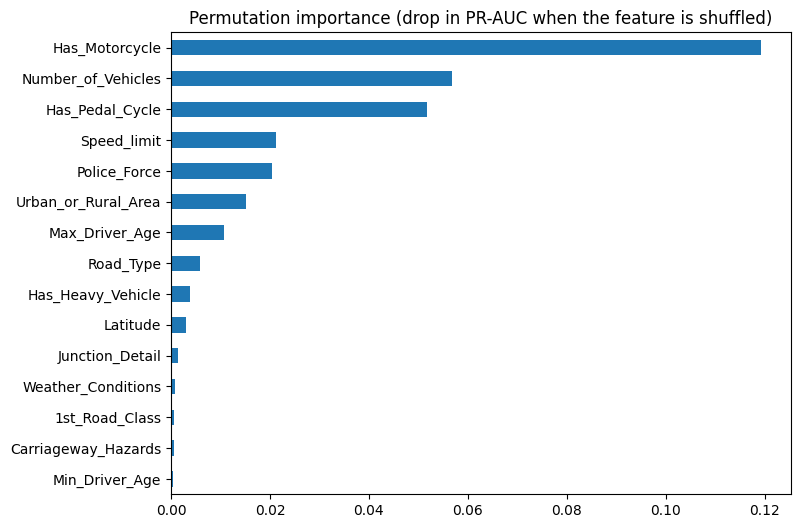

,0
Has_Motorcycle,0.1193
Number_of_Vehicles,0.0568
Has_Pedal_Cycle,0.0517
Speed_limit,0.0211
Police_Force,0.0204
Urban_or_Rural_Area,0.0151
Max_Driver_Age,0.0108
Road_Type,0.0059
Has_Heavy_Vehicle,0.0039
Latitude,0.0031


In [34]:
sample_idx = X_test.sample(min(3000, len(X_test)), random_state=RANDOM_STATE).index
perm = permutation_importance(final_pipe, X_test.loc[sample_idx], y_test.loc[sample_idx], scoring="average_precision",
                              n_repeats=2, random_state=RANDOM_STATE, n_jobs=1)
imp = pd.Series(perm.importances_mean, index=X_test.columns).sort_values(ascending=False)
imp.head(15).sort_values().plot.barh(figsize=(8, 6))
plt.title("Permutation importance (drop in PR-AUC when the feature is shuffled)")
plt.savefig("results/feature_importance.png", bbox_inches="tight")
plt.show()
imp.head(10).round(4)

## 20. Automatic interpretation of the results

In [35]:
top_feats = ", ".join(imp.head(5).index)
print("=== Interpretation ===")
print(f"- Selected model: {best_name} (best CV PR-AUC after GridSearchCV = {tuning_df.loc[best_name, 'After tuning (best_score_)']:.3f}).")
print(f"- Test ROC-AUC = {metrics['test_roc_auc']:.3f} and PR-AUC = {metrics['test_pr_auc']:.3f} (a random model gets PR-AUC = {metrics['random_pr_auc']:.3f}), so the model ranks the accidents much better than chance.")
print(f"- At the chosen threshold ({threshold:.2f}): Recall = {metrics['recall']:.2f}, Precision = {metrics['precision']:.2f}, F1 = {metrics['f1']:.2f}.")
print(f"- The most important features: {top_feats}.")
print(f"- The top 3 models differ by only {float(tuning_df['After tuning (best_score_)'].astype(float).max() - tuning_df['After tuning (best_score_)'].astype(float).min()):.3f} PR-AUC, so the choice between them is not critical.")
print("- Precision is limited: the data has only the conditions of the accident, and many things that decide the severity (exact speed, seat belts, impact angle) are not in it.")

=== Interpretation ===
- Selected model: CatBoost (best CV PR-AUC after GridSearchCV = 0.358).
- Test ROC-AUC = 0.709 and PR-AUC = 0.380 (a random model gets PR-AUC = 0.203), so the model ranks the accidents much better than chance.
- At the chosen threshold (0.51): Recall = 0.64, Precision = 0.32, F1 = 0.43.
- The most important features: Has_Motorcycle, Number_of_Vehicles, Has_Pedal_Cycle, Speed_limit, Police_Force.
- The top 3 models differ by only 0.002 PR-AUC, so the choice between them is not critical.
- Precision is limited: the data has only the conditions of the accident, and many things that decide the severity (exact speed, seat belts, impact angle) are not in it.


## 21. Save the model, the results and the requirements for the app

In [36]:
joblib.dump({"pipeline": final_pipe, "threshold": threshold, "feature_columns": list(X.columns),
             "num_cols": num_cols, "cat_cols": cat_cols}, "models/best_model.joblib", compress=3)   # compressed: the file must stay small for GitHub (< 25 MB)

json.dump(metrics, open("results/final_metrics.json", "w"), indent=2, default=float)
pd.DataFrame({"Hour": [], "Speed_limit": []})   # keeps the cell output small

# requirements.txt with the exact versions used here, so the app (e.g. Hugging Face) loads the model without version problems
from importlib.metadata import version
pkgs = ["scikit-learn", "pandas", "numpy", "joblib", "gradio", "lightgbm", "xgboost", "catboost"]
with open("requirements.txt", "w") as f:
    for p in pkgs:
        try:
            f.write(f"{p}=={version(p)}\n")
        except Exception:
            f.write(p + "\n")
print(open("requirements.txt").read())
print("model size (MB):", round(os.path.getsize("models/best_model.joblib") / 1e6, 1))

scikit-learn==1.6.1
pandas==2.2.3
numpy==2.4.6
joblib==1.6.0
gradio==6.31.0
lightgbm==4.6.0
xgboost==3.4.1
catboost==1.2.10

model size (MB): 0.1


## 22. Test the saved model like the app does
Load the saved file and predict for one example accident, to be sure the app will work.

In [37]:
saved = joblib.load("models/best_model.joblib")
example = X_test.iloc[[0]]
p = saved["pipeline"].predict_proba(example)[0, 1]
print("Probability of Serious/Fatal:", round(p, 3), "-> predicted class:", "Serious/Fatal" if p >= saved["threshold"] else "Slight", "| real:", "Serious/Fatal" if y_test.iloc[0] else "Slight")

Probability of Serious/Fatal: 0.666 -> predicted class: Serious/Fatal | real: Serious/Fatal


In [38]:
# put the files in one zip and download it (Colab)
import shutil
shutil.make_archive("Final_Project_outputs", "zip", ".", "models")
try:
    from google.colab import files
    shutil.make_archive("Final_Project_results", "zip", ".", "results")
    files.download("Final_Project_outputs.zip"); files.download("Final_Project_results.zip"); files.download("requirements.txt")
except Exception:
    print("Not in Colab: the files are in the folders 'models' and 'results'.")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 23. Conclusions and recommendations
- **Result:** the best model is selected by cross-validation and GridSearchCV and evaluated once on the test set (see the numbers above). It ranks serious accidents well above chance, and with the tuned threshold it catches most serious accidents at the cost of false alarms.
- **Main drivers:** see the permutation-importance chart (section 18); the EDA already shows that motorcycles, pedal cycles, high speed limits, rural roads and darkness without lights go with more serious accidents.
- **Recommendations:** focus safety measures (speed control, lighting, barriers, rider protection) on high-speed rural roads and on roads with many motorcycles / cyclists; use the model to rank locations or conditions by risk, **not** to judge individual drivers.
- **Limits:** only one year (2018) and only one country; the exact speed, seat belt use and the angle of impact are not in the data; casualty information was excluded on purpose to avoid leakage; the model predicts the *risk*, it does not explain the *cause*.
- **Possible improvements:** several years of data, weather data by hour, road geometry, more tuning.